# 作业3：NumPy、Matplotlib 与 pandas
1. 尽早开始！如果在安装或导入包时遇到问题，最好提前发现这些问题，而不是在作业截止前一晚。
2. 确保备份您的工作！推荐学习使用 Git。
3. 请先将第一个代码框中的学号修改为自己的学号，再完成以下作业，并按顺序运行各个代码框。

In [1]:
import hashlib
import os
import platform
import uuid
import sys

# 修改为自己的学号
STUDENT_ID = 20244080301

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[Python]   {sys.version.split()[0]}")

[Conda 环境] exp02
[学号]       20244080301
[机器指纹] 4893301fd6adb35f
[RUN_ID]   20244080301-4893301fd6adb35f
[Python]   3.12.15


## 围绕半圆定律
随机矩阵理论研究随机矩阵的性质。对于下述随机对称矩阵，随着矩阵阶数 增⼤，其
特征值的分布趋近于半圆定律。半圆密度为
$$
f(x)=\begin{cases}
\dfrac{1}{2\pi}\sqrt{4-x^{2}}, & |x|\le 2,\\[6pt]
0, & |x|>2.
\end{cases}
$$

构造n*n的对称随机矩阵$Z$：对所有1<=i<=j<=n，独⽴地从均值为0、⽅差为1/n的正态分布抽取$Z_{ij}$ ，再令$Z_{ij}$ = $Z_{ji}$。这样的矩阵称为 Wigner 矩阵。其特征值的标准化直⽅图会随增⼤⽽逐渐接近上述密度曲线。

### 1. 编写 wigner_density(x)，接收⼀个整数或浮点数，返回半圆密度在 处的值，返回值为浮点数。不需要检查输⼊类型；函数应同时适⽤于 Python 和 NumPy的整数、浮点数。计算平⽅根时使⽤ numpy.sqrt，不要使⽤ math.sqrt。

In [2]:
import numpy as np

def wigner_density(x):
    x = float(x)                      # 同时兼容 Python 与 NumPy 的整数、浮点数
    if abs(x) <= 2:
        return float(np.sqrt(4.0 - x * x) / (2.0 * np.pi))
    return 0.0

for v in (0, 1, 2, -2, 2.5, np.int64(1), np.float64(0.5)):
    print(f"f({v}) = {wigner_density(v):.6f}")

f(0) = 0.318310
f(1) = 0.275664
f(2) = 0.000000
f(-2) = 0.000000
f(2.5) = 0.000000
f(1) = 0.275664
f(0.5) = 0.308202


### 2. 编写 generate_wigner(n)，接收正整数 ，返回⼀个随机⽣成的 Wigner 矩阵，可以使⽤ NumPy 的⼆维数组或矩阵表⽰。若输⼊不是整数或不是正数，应抛出合适的异常。

In [3]:
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    # 每个元素独立取自 N(0, 1/n) 的正态分布
    z = np.random.normal(loc=0.0, scale=1.0 / np.sqrt(n), size=(n, n))
    # 用上三角加严格上三角的转置构造对称矩阵：Z_ji = Z_ij
    return np.triu(z) + np.triu(z, 1).T

w = generate_wigner(4)
print(w)
print("是否对称:", np.allclose(w, w.T))

for bad in (0, -3, 2.5, "5"):
    try:
        generate_wigner(bad)
    except (TypeError, ValueError) as e:
        print(f"generate_wigner({bad!r}) -> {type(e).__name__}: {e}")

[[ 0.14715342  1.05453874  0.11697416  0.6228239 ]
 [ 1.05453874 -0.21284487 -0.49327004 -1.23961634]
 [ 0.11697416 -0.49327004 -0.16950196 -0.01898344]
 [ 0.6228239  -1.23961634 -0.01898344 -0.93742286]]
是否对称: True
generate_wigner(0) -> ValueError: n 必须是正整数
generate_wigner(-3) -> ValueError: n 必须是正整数
generate_wigner(2.5) -> TypeError: n 必须是整数
generate_wigner('5') -> TypeError: n 必须是整数


### 3. 编写 get_spectrum(matrix)，接收 NumPy 矩阵或⼆维 NumPy 数组，返回包含其全部特征值的 NumPy 数组，按⾮递减顺序排列。本函数不需要检查输⼊类型。

In [4]:
def get_spectrum(matrix):
    values = np.linalg.eigvalsh(np.asarray(matrix, dtype=float))
    return np.sort(values)          # 非递减顺序

spec = get_spectrum(generate_wigner(5))
print("特征值:", spec)
print("是否非递减:", bool(np.all(np.diff(spec) >= 0)))

特征值: [-1.82462152 -0.68818243 -0.28967546  0.88111326  1.83471626]
是否非递减: True


### 4. 画⼀张包含四个纵向排列⼦图的图。对n=100,200,500,1000，每个⼦图分别⽤蓝⾊、标准化的直⽅图展⽰随机 Wigner 矩阵的特征值，并叠加红⾊的半圆密度曲线。根据图形说明： ⼤约达到多少时，半圆密度能较好地拟合特征值分布？使⽤ Kolmogorov–Smirnov 检验作更严格的⽐较是可选任务。特征值计算可能较慢，尤其是远⼤于 1000 阶的矩阵。

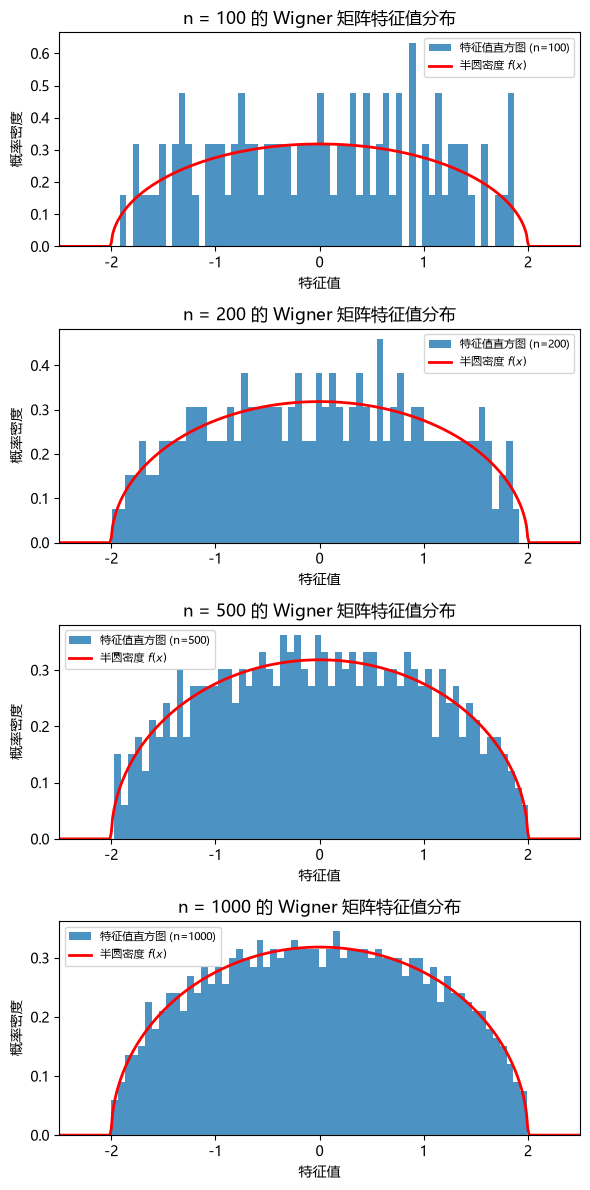

结论：n=100 时直方图与半圆密度曲线还有明显偏差（边缘起伏大、中心偏高）；
n=200 起形状接近，n=500~1000 时直方图轮廓基本贴合理论曲线。
因此大约 n ≥ 500（尤其 1000）时，半圆密度能较好地拟合特征值分布。


In [5]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

np.random.seed(20244080301 % 2**32)

sizes = [100, 200, 500, 1000]
x = np.linspace(-2.5, 2.5, 400)
curve = np.where(np.abs(x) <= 2, np.sqrt(np.clip(4.0 - x * x, 0, None)) / (2.0 * np.pi), 0.0)

fig, axes = plt.subplots(len(sizes), 1, figsize=(6, 12))

for ax, n in zip(axes, sizes):
    eigenvalues = get_spectrum(generate_wigner(n))
    ax.hist(eigenvalues, bins=60, density=True, color="tab:blue", alpha=0.8,
            label=f"特征值直方图 (n={n})")
    ax.plot(x, curve, color="red", linewidth=2, label="半圆密度 $f(x)$")
    ax.set_title(f"n = {n} 的 Wigner 矩阵特征值分布")
    ax.set_xlabel("特征值")
    ax.set_ylabel("概率密度")
    ax.set_xlim(-2.5, 2.5)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("结论：n=100 时直方图与半圆密度曲线还有明显偏差（边缘起伏大、中心偏高）；")
print("n=200 起形状接近，n=500~1000 时直方图轮廓基本贴合理论曲线。")
print("因此大约 n ≥ 500（尤其 1000）时，半圆密度能较好地拟合特征值分布。")

## Conway 的⽣命游戏
⽣命游戏在⼀个m*n棋盘上进⾏，棋盘⽤ NumPy 的⼆维数组表⽰：活细胞记为 1，死细胞记为 0。每⼀步按以下规则同时更新所有细胞：

活细胞有少于两个活邻居时死亡；

活细胞有两个或三个活邻居时继续存活；

活细胞有多于三个活邻居时死亡；

死细胞恰好有三个活邻居时复活；

其他死细胞保持死亡。
每个细胞有上、下、左、右和四个对⻆⽅向的邻居，共⼋个。棋盘采⽤环绕边界：例如，位置 (0, 0) 上⽅的邻居是 (m-1, 0)，位置 (m-1, n-1) 右侧的邻居是 (m-1,0)。

### 1. 编写 is_valid_board(board)，接收⼀个 NumPy ndarray，若它是有效的⽣命游戏棋盘（⼆维、元素仅为 0 或 1）则返回 Python 布尔值 True，否则返回False。

In [6]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.isin(board, (0, 1)).all())

print(is_valid_board(np.array([[0, 1], [1, 0]])))
print(is_valid_board(np.array([[0, 1], [1, 2]])))
print(is_valid_board(np.array([0, 1])))
print(is_valid_board([[0, 1], [1, 0]]))

True
False
False
False


### 2. 编写 gol_step(board)，接收⼀个 棋盘，返回同样⼤⼩的 NumPy 数组，表⽰下⼀步的棋盘。函数应先检查输⼊是否为有效棋盘，⽆效时抛出合适的异常。计算某个细胞的下⼀状态时，应使⽤原棋盘中的邻居状态。

In [7]:
def count_neighbors(board):
    # 环绕边界：用 np.roll 平移累加八个方向的邻居
    total = np.zeros_like(board, dtype=int)
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if (dr, dc) != (0, 0):
                total += np.roll(np.roll(board, dr, axis=0), dc, axis=1)
    return total

def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘（二维且元素仅为 0/1）")
    board = board.astype(int)
    neighbors = count_neighbors(board)
    alive = board == 1
    birth = (board == 0) & (neighbors == 3)          # 死细胞恰好 3 个活邻居
    survive = alive & ((neighbors == 2) | (neighbors == 3))
    return (birth | survive).astype(int)

# 在 8x8 的环绕棋盘上放一个滑翔机（glider），它每一步沿对角线移动一格
glider = np.zeros((8, 8), dtype=int)
glider[1:4, 1:4] = [[0, 1, 0],
                    [0, 0, 1],
                    [1, 1, 1]]

print("当前棋盘:")
print(glider)
print("下一步:")
print(gol_step(glider))
print("再下一步:")
print(gol_step(gol_step(glider)))

# 环绕边界示例：左上角 (0, 0) 的三个活邻居可来自右下角
corner = np.zeros((5, 5), dtype=int)
corner[4, 4] = corner[4, 0] = corner[0, 4] = 1
print("角落测试：棋盘")
print(corner)
print("角上细胞 (0,0) 的活邻居数:", count_neighbors(corner)[0, 0], "(通过环绕边界统计到 3 个)")

try:
    gol_step(np.array([[0, 2]]))
except ValueError as e:
    print("ValueError:", e)

当前棋盘:
[[0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 1 1 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
下一步:
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 1 0 1 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
再下一步:
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 1 0 1 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
角落测试：棋盘
[[0 0 0 0 1]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [1 0 0 0 1]]
角上细胞 (0,0) 的活邻居数: 3 (通过环绕边界统计到 3 个)
ValueError: 输入不是有效的生命游戏棋盘（二维且元素仅为 0/1）


### 3. 编写 draw_gol_board(board)，将棋盘画成 个⽅格：活细胞为⿊⾊，死细胞为⽩⾊。图中不显⽰⽹格线、轴标签或轴刻度。可以使⽤plt.xticks()、plt.yticks() 和 plt.get_cmap() 等函数。

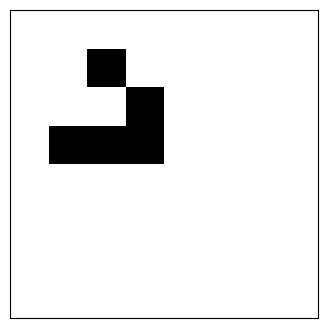

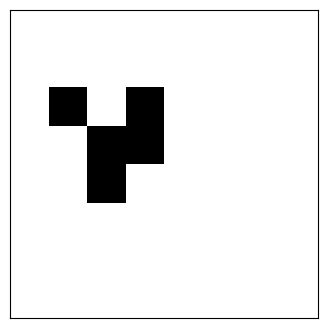

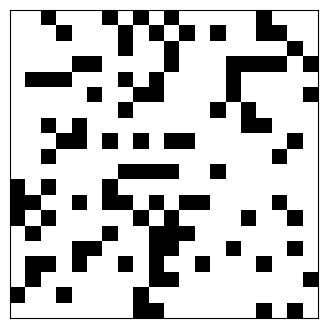

In [8]:
def draw_gol_board(board):
    fig, ax = plt.subplots(figsize=(4, 4))
    # gray_r：0 -> 白色（死细胞），1 -> 黑色（活细胞）
    ax.imshow(np.asarray(board), cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    plt.show()

glider = np.zeros((8, 8), dtype=int)
glider[1:4, 1:4] = [[0, 1, 0],
                    [0, 0, 1],
                    [1, 1, 1]]
draw_gol_board(glider)
draw_gol_board(gol_step(glider))

# 也可以画一个随机初始棋盘
np.random.seed(20244080301 % 2**32)
random_board = (np.random.random((20, 20)) < 0.3).astype(int)
draw_gol_board(random_board)

## 使⽤ pandas DataFrame
本题练习读取、修改和保存 DataFrame，以及按组汇总数据。

### 1. 下载 iris.csv(www.kaggle.com/datasets/gradylynn/iris-csv)。使⽤ pandas 将它读⼊为 DataFrame；CSV 的第⼀⾏是列标题。回答：数据集有多少个数据点？每列是什么数据类型？列名是什么？数据中有多少种花卉？列名对应花卉种类，以及花瓣⻓度、花瓣宽度、萼⽚⻓度和萼⽚宽度四项测量。

In [9]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"E:\python实验课\hw03_data")
csv_path = DATA_DIR / "archive" / "iris.csv"

df = pd.read_csv(csv_path)

# 第一列是无名的行号，删掉它，改用从 0 开始的默认行索引（0..149）
if str(df.columns[0]).startswith("Unnamed"):
    df = df.drop(columns=df.columns[0])

# ---- 识别“花卉种类”列 ----
# 有的 iris.csv 种类列叫 species / Species / variety，也可能是 0/1/2 的编码；
# 都可以自动识别。这份下载的文件确实没有种类列，此时按标准 iris 顺序补上。
SPECIES_MAP = {0: "setosa", 1: "versicolor", 2: "virginica"}

def find_species_column(data):
    for col in data.columns:
        if str(data[col].dtype) not in ("object", "str", "string", "category"):
            continue
        values = {str(v) for v in data[col].dropna().unique()}
        if {"setosa", "versicolor", "virginica"} & values:
            return col
    return None

found = find_species_column(df)
if found is not None:
    df = df.rename(columns={found: "species"})
    print(f"已从列 {found!r} 读取花卉种类")
elif "target" in df.columns:
    df["species"] = df["target"].map(SPECIES_MAP)
    print("已把 target 列（0/1/2）映射为花卉种类")
else:
    df["species"] = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50
    print("提示：该 CSV 中没有花卉种类列，已按标准 iris 数据顺序（各 50 条）补上 species")

print()
print("数据点数量:", len(df))
print("列名:", list(df.columns))
print("每列数据类型:")
print(df.dtypes)
print("花卉种类数:", df["species"].nunique(), "->", list(df["species"].unique()))
print("各类数量:")
print(df["species"].value_counts())
print()
print("列名含义:")
print("  sepal length (cm)  萼片长度")
print("  sepal width (cm)   萼片宽度")
print("  petal length (cm)  花瓣长度")
print("  petal width (cm)   花瓣宽度")
print("  species            花卉种类")
print()
print("数据质量检查 —— 含空值的行:")
print(df[df.isna().any(axis=1)])
print()
print(df.head())

提示：该 CSV 中没有花卉种类列，已按标准 iris 数据顺序（各 50 条）补上 species

数据点数量: 150
列名: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']
每列数据类型:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object
花卉种类数: 3 -> ['setosa', 'versicolor', 'virginica']
各类数量:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

列名含义:
  sepal length (cm)  萼片长度
  sepal width (cm)   萼片宽度
  petal length (cm)  花瓣长度
  petal width (cm)   花瓣宽度
  species            花卉种类

数据质量检查 —— 含空值的行:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
24                NaN               3.4                1.9               0.2   
37                4.9               3.6                NaN               0.1   
56                6.3               NaN                4.7               1.6   

       species  
24      setosa  
37      setosa  
56  

### 2. 已知数据的第 35 个和第 38 个数据⾏有误（不计列标题）。将第 35 ⾏改为4.9,3.1,1.5,0.2,"setosa"，其中原⽂件的第四项测量有误；将第 38 ⾏改为4.9,3.6,1.4,0.1,"setosa"，其中原⽂件的第⼆、三项测量有误。请在DataFrame 中完成修改，并检查修改后的两⾏。若采⽤从 0 开始的默认⾏索引，这两⾏的索引分别是 34 和 37。

In [10]:
COLS = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)", "species"]

print("修改前的第 35 行（索引 34）:")
print(df.loc[34, COLS])
print("修改前的第 38 行（索引 37）:")
print(df.loc[37, COLS])

# 题目指定的第 35 行、第 38 行更正（索引 34、37）
df.loc[34, COLS] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, COLS] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print()
print("修改后的两行:")
print(df.loc[[34, 37], COLS])
print()

修改前的第 35 行（索引 34）:
sepal length (cm)       4.9
sepal width (cm)        3.1
petal length (cm)       1.5
petal width (cm)        0.2
species              setosa
Name: 34, dtype: object
修改前的第 38 行（索引 37）:
sepal length (cm)       4.9
sepal width (cm)        3.6
petal length (cm)       NaN
petal width (cm)        0.1
species              setosa
Name: 37, dtype: object

修改后的两行:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
34                4.9               3.1                1.5               0.2   
37                4.9               3.6                1.4               0.1   

   species  
34  setosa  
37  setosa  



### 3. 添加两列新特征：Petal.Ratio 为花瓣⻓度除以花瓣宽度；Sepal.Ratio 为萼⽚⻓度除以萼⽚宽度。

In [11]:
df["Petal.Ratio"] = df["petal length (cm)"] / df["petal width (cm)"]
df["Sepal.Ratio"] = df["sepal length (cm)"] / df["sepal width (cm)"]

print(df.head())
print()
print("Petal.Ratio 统计:")
print(df["Petal.Ratio"].describe().round(4))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  Petal.Ratio  Sepal.Ratio  
0  setosa          7.0     1.457143  
1  setosa          7.0     1.633333  
2  setosa          6.5     1.468750  
3  setosa          7.5     1.483871  
4  setosa          7.0     1.388889  

Petal.Ratio 统计:
count    150.0000
mean       4.2904
std        2.5096
min        0.3357
25%        2.7921
50%        3.2929
75%        4.6667
max       15.0000
Name: Petal.Ratio, dtype: float64


### 4. 将更正并扩展后的 DataFrame 保存为 iris_corrected.csv，并随作业提交。

In [12]:
out_path = DATA_DIR / "iris_corrected.csv"
df.to_csv(out_path, index=False)

print("已保存到:", out_path)
print("文件存在:", out_path.exists(), "大小:", out_path.stat().st_size, "字节")
print("保存的行数:", len(df), "列数:", len(df.columns))
print()
print(pd.read_csv(out_path).head())

已保存到: E:\python实验课\hw03_data\iris_corrected.csv
文件存在: True 大小: 8461 字节
保存的行数: 150 列数: 7

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  Petal.Ratio  Sepal.Ratio  
0  setosa          7.0     1.457143  
1  setosa          7.0     1.633333  
2  setosa          6.5     1.468750  
3  setosa          7.5     1.483871  
4  setosa          7.0     1.388889  


### 5. 按花卉种类分组，分别计算 Petal.Ratio 和 Sepal.Ratio 的平均值、中位数、最⼩值、最⼤值和标准差。使⽤合适的 groupby() 或聚合操作⼀次获得这些结果。

In [13]:
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)

print(summary.round(4))
print()
print("按列查看更直观:")
print(summary.stack(level=0).round(4))

           Petal.Ratio                               Sepal.Ratio          \
                  mean  median     min   max     std        mean  median   
species                                                                    
setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4714  1.4667   
versicolor      3.1824  3.2308  0.3357   4.1  0.5159      2.1655  2.1613   
virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                    
               min     max     std  
species                             
setosa      1.2683  1.9565  0.1197  
versicolor  1.7647  2.8182  0.2281  
virginica   1.8235  2.9615  0.2470  

按列查看更直观:
                          mean  median     min      max     std
species                                                        
setosa     Petal.Ratio  6.9080  7.0000  2.6667  15.0000  2.8545
           Sepal.Ratio  1.4714  1.4667  1.2683   1.9565  0.1197
versicolor Petal.Ratio  3.1824  3.2308  0.3357   4.1000